<a href="https://colab.research.google.com/github/starsyntaxx/MarketIQ/blob/main/notebooks/01_data_understanding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import zipfile
import os

In [4]:

def extract_file_from_drive(zip_path, file_name, extract_to='/content/extracted'):

    os.makedirs(extract_to, exist_ok=True)

    with zipfile.ZipFile(zip_path, 'r') as zip_ref:

        if file_name not in zip_ref.namelist():
            raise FileNotFoundError(
                f"{file_name} not found in the ZIP archive."
            )

        zip_ref.extract(file_name, extract_to)

    extracted_path = os.path.join(extract_to, file_name)

    return extracted_path

In [5]:
zip_path = "/content/drive/MyDrive/ML PROJECTS/MarketIQ/data/raw/NGA_2025_HFCP_v01_M_CSV.zip"

In [6]:
import zipfile

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    print(zip_ref.namelist())

['Raw_data_spatialrev.csv', 'level2_price_yellow_maize.csv', 'level2_price_yam.csv', 'level2_price_white_maize.csv', 'level2_price_white_beans.csv', 'level2_price_soybean.csv', 'level2_price_sorghum.csv', 'level2_price_local_rice.csv', 'level2_price_imported_rice.csv', 'level2_price_garri.csv', 'level2_price_brown_beans.csv']


In [7]:
file_path = extract_file_from_drive(
    zip_path=zip_path,
    file_name='level2_price_white_beans.csv'
)

print(file_path)

/content/extracted/level2_price_white_beans.csv


In [8]:
import pandas as pd

df = pd.read_csv(file_path)

df.head(20)

,fid,submissio,date,zonecode1,geopol_zon,statecode1,zonelabel1,statelabel,lga,lgalabel,...,market_tim,gps_latitu,gps_longit,count,month,price,commodity,daily_mean,daily_sd,outlier_flag
0,6,6538,12/3/2024,5,nbssouthsouth,6,South South,BAYELSA,603,KOLOKUMA/OPOKUMA,...,15,5.127898,6.296028,1,Dec,1860.000000,White Beans,1998.126814,728.108298,non-outlier
1,7,6539,12/3/2024,5,nbssouthsouth,6,South South,BAYELSA,603,KOLOKUMA/OPOKUMA,...,20,5.127898,6.296028,1,Dec,1800.000000,White Beans,1998.126814,728.108298,non-outlier
2,9,6635,12/3/2024,3,nbsnorthwest,20,North West,KATSINA,2021,KATSINA,...,2,12.980655,7.585523,1,Dec,2000.000000,White Beans,1998.126814,728.108298,non-outlier
3,16,11821,12/8/2024,1,nbsnorthcentral,25,North Central,NASARAWA,2504,KARU,...,10,9.027698,7.600418,1,Dec,1785.714286,White Beans,1967.629207,682.166115,non-outlier
4,17,11825,12/8/2024,1,nbsnorthcentral,25,North Central,NASARAWA,2504,KARU,...,8,9.027698,7.600418,1,Dec,1928.571429,White Beans,1967.629207,682.166115,non-outlier
5,26,16389,12/12/2024,4,nbssoutheast,14,South East,ENUGU,1405,ENUGU SOUTH,...,15,6.404536,7.488134,1,Dec,2500.000000,White Beans,1921.753726,695.224154,non-outlier
6,27,16390,12/12/2024,4,nbssoutheast,14,South East,ENUGU,1405,ENUGU SOUTH,...,39,6.404201,7.494098,1,Dec,2500.000000,White Beans,1921.753726,695.224154,non-outlier
7,28,16391,12/12/2024,4,nbssoutheast,14,South East,ENUGU,1405,ENUGU SOUTH,...,30,6.403089,7.493365,1,Dec,2500.000000,White Beans,1921.753726,695.224154,non-outlier
8,32,18836,12/14/2024,4,nbssoutheast,14,South East,ENUGU,1405,ENUGU SOUTH,...,43,6.406223,7.492665,1,Dec,2500.000000,White Beans,1961.174786,692.706973,non-outlier
9,34,18839,12/14/2024,4,nbssoutheast,14,South East,ENUGU,1405,ENUGU SOUTH,...,57,6.408643,7.488483,1,Dec,2500.000000,White Beans,1961.174786,692.706973,non-outlier


## Dataset Variable Description

The dataset contains the following variables and their corresponding descriptions:

| ID | Variable Name | Description |
|:---|:---|:---|
| V1 | `fid` | Field ID for the data record, based on the overall dataset. |
| V2 | `submissio` | System-assigned submission ID for each price data record. |
| V3 | `date` | Date of data submission. |
| V4 | `zonecode1` | Officially assigned code for the geopolitical zone. |
| V5 | `geopol_zon` | Assigned codename for the geopolitical zone. |
| V6 | `statecode1` | Assigned code for the state. |
| V7 | `zonelabel1` | Geopolitical zone. |
| V8 | `statelabel` | Name of the administrative state. |
| V9 | `lga` | Assigned ID for the Local Government Area (LGA). |
| V10 | `lgalabel` | Name of the Local Government Area (LGA). |
| V11 | `sector` | Binary coding for the geographical context (rural or urban). |
| V12 | `staff_vali` | Number that differentiates crowdsourced data from validation data. |
| V13 | `consent` | Number indicating whether the vendor consents to providing price data. |
| V14 | `market_typ` | Type of market where price data was sourced. |
| V15 | `price_cate` | Market segment of the price outlet. |
| V16 | `market_tim` | Estimated travel time to the market outlet, in minutes. |
| V18 | `gps_latitu` | Geographic GPS latitude. |
| V19 | `gps_longit` | Geographic GPS longitude. |
| V20 | `count` | Dummy unitary variable for counting data records. |
| V22 | `month` | Month of data submission. |
| V24 | `price` | Observed price calculated per kilogram, in Nigerian Naira (₦). |
| V25 | `commodity` | Name of the commodity. |
| V26 | `daily_mean` | Calculated mean of all price submissions made during a specific day, in Naira per kilogram. |
| V27 | `daily_sd` | Calculated standard deviation of all price submissions made during a specific day. |
| V28 | `outlier_flag` | Outlier designation based on 2.5 times the standard deviation. |

### Notes
- Prices are expressed in Nigerian Naira (₦) per kilogram.
- Geographic variables provide information about the location of each market.
- `staff_vali` helps distinguish crowdsourced submissions from validation data.
- `daily_mean` and `daily_sd` provide daily statistical summaries of commodity prices.
- `outlier_flag` identifies potentially unusual price observations based on the standard deviation threshold.

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 202059 entries, 0 to 202058
Data columns (total 25 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   fid           202059 non-null  int64  
 1   submissio     202059 non-null  int64  
 2   date          202059 non-null  object 
 3   zonecode1     202059 non-null  int64  
 4   geopol_zon    202059 non-null  object 
 5   statecode1    202059 non-null  int64  
 6   zonelabel1    202059 non-null  object 
 7   statelabel    202059 non-null  object 
 8   lga           202059 non-null  int64  
 9   lgalabel      202059 non-null  object 
 10  sector        202059 non-null  object 
 11  staff_vali    202059 non-null  int64  
 12  consent       202059 non-null  int64  
 13  market_typ    202059 non-null  object 
 14  price_cate    202059 non-null  object 
 15  market_tim    202059 non-null  int64  
 16  gps_latitu    202059 non-null  float64
 17  gps_longit    202059 non-null  float64
 18  coun

In [10]:
df.describe()

,fid,submissio,zonecode1,statecode1,lga,staff_vali,consent,market_tim,gps_latitu,gps_longit,count,price,daily_mean,daily_sd
count,202059.000000,202059.000000,202059.000000,202059.000000,202059.000000,202059.000000,202059.0,2.020590e+05,202059.000000,202059.000000,202059.0,202059.000000,202059.000000,202059.000000
mean,109860.418383,115990.081070,3.432824,19.613791,1972.844832,0.111062,1.0,6.062553e+03,8.660558,7.310543,1.0,1701.729641,1799.357333,748.497657
std,63409.028481,62079.298111,1.778112,10.288456,1027.844088,0.314209,0.0,1.912650e+06,2.493766,2.471863,0.0,537.485659,125.974258,48.557732
min,6.000000,6249.000000,1.000000,1.000000,101.000000,0.000000,1.0,-8.500000e+01,4.426009,2.714769,1.0,100.000000,1608.639962,624.704217
25%,54859.500000,62551.500000,2.000000,11.000000,1104.000000,0.000000,1.0,1.000000e+01,6.573922,5.249431,1.0,1250.000000,1698.680360,718.796247
50%,109903.000000,116203.000000,3.000000,20.000000,2020.000000,0.000000,1.0,2.000000e+01,8.165061,7.367033,1.0,1678.571429,1733.014010,747.071268
75%,164636.500000,169656.500000,5.000000,29.000000,2902.000000,0.000000,1.0,4.000000e+01,10.649415,8.539809,1.0,2000.000000,1935.207221,779.002383
max,220213.000000,223519.000000,6.000000,37.000000,3706.000000,1.000000,1.0,6.584807e+08,13.754103,14.209325,1.0,4285.714286,2058.411893,932.402245


### 1. Data Cleaning & Temporal Alignment
Let's convert the `date` column to datetime and check the date range of our dataset.

In [11]:
df['date'] = pd.to_datetime(df['date'])
print(f"Data Date Range: {df['date'].min()} to {df['date'].max()}")

Data Date Range: 2024-12-03 00:00:00 to 2025-06-29 00:00:00


### 2. Checking Anomalies
Let's check the distribution of the travel time (`market_tim`) and filter out anomalous records (e.g., extremely high travel times or negative values) to understand our operational boundaries.

In [12]:
negative_times = (df['market_tim'] < 0).sum()
extreme_times = (df['market_tim'] > 480).sum()  # over 8 hours
print(f"Submissions with negative market travel times: {negative_times}")
print(f"Submissions with > 8 hours travel time: {extreme_times}")

Submissions with negative market travel times: 14
Submissions with > 8 hours travel time: 206


### 3. Baseline Summary by Geopolitical Zone
Let's group by geopolitical zone to analyze the volume of records, average price, and average travel time.

In [13]:
zone_summary = df.groupby('zonelabel1').agg(
    record_count=('fid', 'count'),
    mean_price=('price', 'mean'),
    median_price=('price', 'median'),
    mean_travel_time=('market_tim', 'mean')
).reset_index().sort_values(by='mean_price', ascending=False)

display(zone_summary)

,zonelabel1,record_count,mean_price,median_price,mean_travel_time
3,South East,20183,2089.256867,2000.000000,32693.347272
4,South South,29008,2080.691385,2000.000000,259.220456
2,North West,44261,1760.539919,1785.714286,33.182621
1,North East,30102,1651.751179,1714.285714,33.970135
5,South West,39276,1454.875400,1250.000000,31.968683
0,North Central,39229,1441.272144,1428.571429,14119.077927


### 4. Baseline Visualizations
We'll visualize the overall distribution of price per kg and display average price comparisons across different regions.

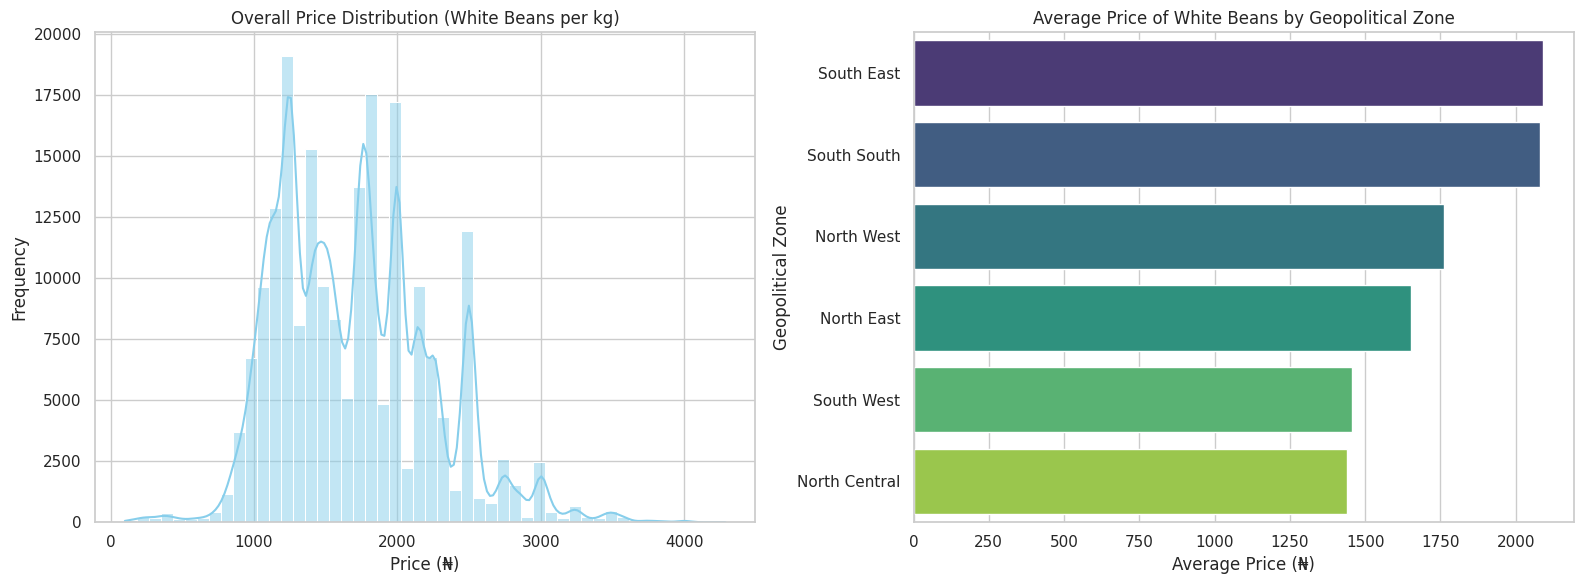

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Price Distribution
sns.histplot(df['price'], bins=50, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Overall Price Distribution (White Beans per kg)')
axes[0].set_xlabel('Price (₦)')
axes[0].set_ylabel('Frequency')

# Subplot 2: Average Price by Geopolitical Zone
sns.barplot(x='mean_price', y='zonelabel1', data=zone_summary, ax=axes[1], palette='viridis', hue='zonelabel1', legend=False)
axes[1].set_title('Average Price of White Beans by Geopolitical Zone')
axes[1].set_xlabel('Average Price (₦)')
axes[1].set_ylabel('Geopolitical Zone')

plt.tight_layout()
plt.show()